<a href="https://colab.research.google.com/github/FrankEHA/INGENIERIA_DEL_CONOCIMIENTO/blob/main/EJERCICIO_ADICIONAL_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Ejercicio 1.1: Exploración del dataset Diabetes***

**Contexto:** antes de entrenar un modelo de regresión (que predice una variable continua) conviene hacer un análisis exploratorio para entender los datos y ver qué variables se relacionan más con lo que queremos predecir.

**Dataset:** load_diabetes() tiene 442 pacientes, 10 features clínicas ya normalizadas (age, sex, bmi, bp y s1 a s6, que son mediciones de suero sanguíneo) y un target continuo: la progresión de la enfermedad un año después.

**Objetivo:** identificar qué features aportan más para predecir la progresión, usando estadísticas, correlación de Pearson y gráficos.

**1. Importar librerías y cargar el dataset como DataFrame**

Se carga load_diabetes() y se convierte a DataFrame, agregando el target como columna.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes

data = load_diabetes()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


**2. Dimensiones, nombres de features y estadísticas descriptivas**

Se revisa el tamaño del dataset (442 muestras, 10 features + target), los nombres de las variables y el resumen estadístico.

In [8]:
print("Dimensiones:", df.shape)
print("Features:", data.feature_names)
print()
df.describe().round(4)

Dimensiones: (442, 11)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']



,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000
mean,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,152.1335
std,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,77.0930
min,-0.1072,-0.0446,-0.0903,-0.1124,-0.1268,-0.1156,-0.1023,-0.0764,-0.1261,-0.1378,25.0000
25%,-0.0373,-0.0446,-0.0342,-0.0367,-0.0342,-0.0304,-0.0351,-0.0395,-0.0332,-0.0332,87.0000
50%,0.0054,-0.0446,-0.0073,-0.0057,-0.0043,-0.0038,-0.0066,-0.0026,-0.0019,-0.0011,140.5000
75%,0.0381,0.0507,0.0312,0.0356,0.0284,0.0298,0.0293,0.0343,0.0324,0.0279,211.5000
max,0.1107,0.0507,0.1706,0.1320,0.1539,0.1988,0.1812,0.1852,0.1336,0.1356,346.0000


**3. Correlación de cada feature con el target**

Se calcula la correlación de Pearson de cada feature con el target y se ordena por valor absoluto.

In [9]:
corr = df.corr()['target'].drop('target')
corr_ordenada = corr.reindex(corr.abs().sort_values(ascending=False).index)
print(corr_ordenada.round(4))

bmi    0.5865
s5     0.5659
bp     0.4415
s4     0.4305
s3    -0.3948
s6     0.3825
s1     0.2120
age    0.1879
s2     0.1741
sex    0.0431
Name: target, dtype: float64


**4. Scatter plots de los 4 features más correlacionados**

Se toman los 4 features con mayor correlación absoluta y se grafica cada uno contra el target.

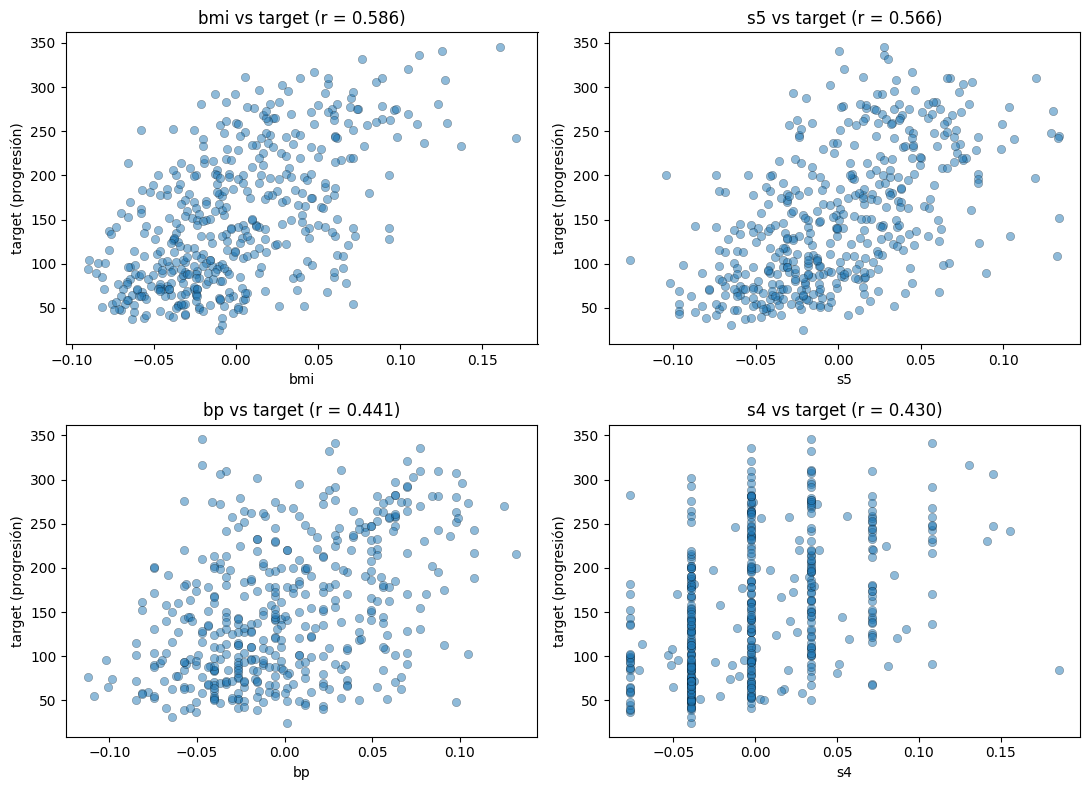

In [10]:
top4 = corr_ordenada.index[:4]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.ravel(), top4):
    ax.scatter(df[feat], df['target'], alpha=0.5, edgecolor='k', linewidth=0.3)
    ax.set_xlabel(feat)
    ax.set_ylabel('target (progresión)')
    ax.set_title(f'{feat} vs target (r = {corr[feat]:.3f})')
plt.tight_layout()
plt.show()

**5. Histograma del target**

Se visualiza la distribución del target (progresión de la enfermedad un año después del inicio) junto con su media, mediana y asimetría.

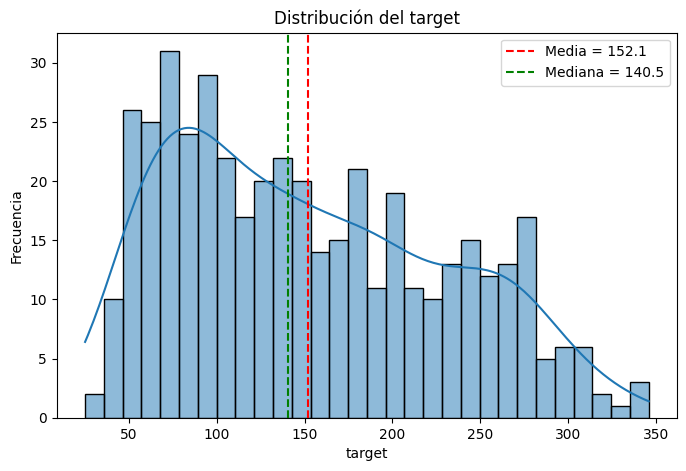

Asimetría (skewness): 0.4406


In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(df['target'], bins=30, kde=True)
plt.axvline(df['target'].mean(), color='red', linestyle='--', label=f"Media = {df['target'].mean():.1f}")
plt.axvline(df['target'].median(), color='green', linestyle='--', label=f"Mediana = {df['target'].median():.1f}")
plt.xlabel('target')
plt.ylabel('Frecuencia')
plt.title('Distribución del target')
plt.legend()
plt.show()

print("Asimetría (skewness):", round(df['target'].skew(), 4))

**6. Respuesta: ¿qué features parecen más útiles?**

Se resume el resultado del paso 3 en una respuesta escrita (celda de texto o print).

In [12]:
print("Features más útiles según su correlación con el target:")
for feat in top4:
    print(f"  - {feat}: r = {corr[feat]:.3f}")

Features más útiles según su correlación con el target:
  - bmi: r = 0.586
  - s5: r = 0.566
  - bp: r = 0.441
  - s4: r = 0.430


# ***Ejercicio 1.2: Mi primera regresión lineal***

Contexto: la regresión lineal simple ajusta una recta y = b0 + b1·x con un solo feature. Aquí usamos bmi y luego comparamos con un modelo que usa los 10 features. Las métricas son RMSE (error típico, en unidades del target), MAE (error absoluto promedio) y R² (proporción de la varianza explicada).

**1. Cargar datos y dividir en train/test**

Se separa el 80% para entrenar y el 20% para evaluar.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

data = load_diabetes(as_frame=True)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**2. Regresión lineal simple con bmi**

Se entrena el modelo usando solo la columna bmi.

In [14]:
modelo_bmi = LinearRegression()
modelo_bmi.fit(X_train[['bmi']], y_train)

print("Intercepto:", round(modelo_bmi.intercept_, 3))
print("Pendiente:", round(modelo_bmi.coef_[0], 3))

Intercepto: 152.003
Pendiente: 998.578


**3. Scatter con la recta de regresión**

Se grafican los datos de test y la recta ajustada encima.

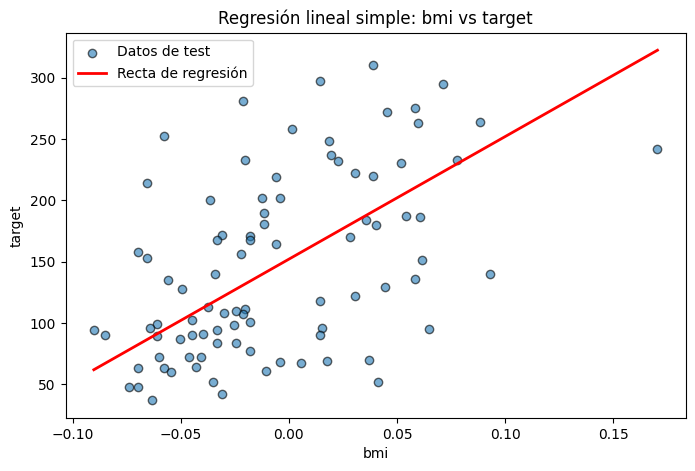

In [15]:
x_linea = np.linspace(X['bmi'].min(), X['bmi'].max(), 100).reshape(-1, 1)
y_linea = modelo_bmi.predict(pd.DataFrame(x_linea, columns=['bmi']))

plt.figure(figsize=(8, 5))
plt.scatter(X_test['bmi'], y_test, alpha=0.6, edgecolor='k', label='Datos de test')
plt.plot(x_linea, y_linea, color='red', linewidth=2, label='Recta de regresión')
plt.xlabel('bmi')
plt.ylabel('target')
plt.title('Regresión lineal simple: bmi vs target')
plt.legend()
plt.show()

**4. Métricas del modelo simple (RMSE, MAE, R²)**

Se define una función para calcular las tres métricas y se aplica al modelo con bmi.

In [16]:
def metricas(y_real, y_pred):
    return {
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'MAE': mean_absolute_error(y_real, y_pred),
        'R²': r2_score(y_real, y_pred)
    }

met_bmi = metricas(y_test, modelo_bmi.predict(X_test[['bmi']]))
met_bmi

{'RMSE': np.float64(63.73245584860925),
 'MAE': 52.259976445345536,
 'R²': 0.23335039815872138}

**5. Regresión lineal con todos los features y comparación**

Se entrena un segundo modelo con los 10 features y se arma una tabla comparativa.

In [17]:
modelo_todos = LinearRegression()
modelo_todos.fit(X_train, y_train)

met_todos = metricas(y_test, modelo_todos.predict(X_test))

tabla = pd.DataFrame({'Solo bmi': met_bmi, 'Todos los features': met_todos}).T
tabla.round(4)

,RMSE,MAE,R²
Solo bmi,63.7325,52.2600,0.2334
Todos los features,53.8534,42.7941,0.4526


**6. Respuesta: ¿cuánto mejora el R² y por qué?**

Se calcula la mejora y se escribe la explicación.

In [18]:
mejora = met_todos['R²'] - met_bmi['R²']
print(f"R² solo bmi: {met_bmi['R²']:.4f}")
print(f"R² todos:    {met_todos['R²']:.4f}")
print(f"Mejora:      {mejora:.4f}")

R² solo bmi: 0.2334
R² todos:    0.4526
Mejora:      0.2193


# ***Ejercicio 1.3: Efecto del Train/Test Split***

Contexto: el resultado de un modelo depende de cómo se divide el dataset. Aquí medimos cómo cambia el R² al variar la proporción de test y la semilla aleatoria (random_state), usando California Housing (20,640 muestras, 8 features, target: valor medio de la vivienda).

**1. Cargar el dataset**

Se descarga California Housing.

In [21]:
import pandas as pd
import numpy as np

try:
    from sklearn.datasets import fetch_california_housing
    housing = fetch_california_housing(as_frame=True)
    X, y = housing.data, housing.target
    print("Cargado desde sklearn")
except Exception as e:
    print("Falló la descarga, usando sample_data de Colab:", type(e).__name__)
    raw = pd.concat([
        pd.read_csv('/content/sample_data/california_housing_train.csv'),
        pd.read_csv('/content/sample_data/california_housing_test.csv')
    ], ignore_index=True)

    X = pd.DataFrame({
        'MedInc':     raw['median_income'],
        'HouseAge':   raw['housing_median_age'],
        'AveRooms':   raw['total_rooms'] / raw['households'],
        'AveBedrms':  raw['total_bedrooms'] / raw['households'],
        'Population': raw['population'],
        'AveOccup':   raw['population'] / raw['households'],
        'Latitude':   raw['latitude'],
        'Longitude':  raw['longitude'],
    })
    y = (raw['median_house_value'] / 100000).rename('MedHouseVal')

print(X.shape)
X.head()

Falló la descarga, usando sample_data de Colab: HTTPError
(20000, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,1.4936,15.0,11.889831,2.718220,1015.0,2.150424,34.19,-114.31
1,1.8200,19.0,16.522678,4.105832,1129.0,2.438445,34.40,-114.47
2,1.6509,17.0,6.153846,1.487179,333.0,2.846154,33.69,-114.56
3,3.1917,14.0,6.641593,1.491150,515.0,2.278761,33.64,-114.57
4,1.9250,20.0,5.549618,1.244275,624.0,2.381679,33.57,-114.57


**2. Regresión lineal con 4 proporciones de test**

Se entrena con test de 10%, 20%, 30% y 50%, y se reporta R² en train y test.

In [22]:
resultados_size = []
for ts in [0.10, 0.20, 0.30, 0.50]:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=ts, random_state=42)
    lr = LinearRegression().fit(X_tr, y_tr)
    resultados_size.append({
        'test_size': ts,
        'n_train': len(X_tr),
        'R² train': r2_score(y_tr, lr.predict(X_tr)),
        'R² test': r2_score(y_te, lr.predict(X_te))
    })

tabla_size = pd.DataFrame(resultados_size)
tabla_size.round(4)

,test_size,n_train,R² train,R² test
0,0.1,18000,0.6044,0.6388
1,0.2,16000,0.6067,0.6121
2,0.3,14000,0.6078,0.6049
3,0.5,10000,0.6109,0.6020


**3. Variar el random_state (test_size = 0.2)**

Se repite el entrenamiento con semillas 0, 7, 42 y 99, y se reporta el R².

In [23]:
resultados_seed = []
for rs in [0, 7, 42, 99]:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=rs)
    lr = LinearRegression().fit(X_tr, y_tr)
    resultados_seed.append({
        'random_state': rs,
        'R² train': r2_score(y_tr, lr.predict(X_tr)),
        'R² test': r2_score(y_te, lr.predict(X_te))
    })

tabla_seed = pd.DataFrame(resultados_seed)
tabla_seed.round(4)

,random_state,R² train,R² test
0,0,0.6146,0.5243
1,7,0.6096,0.6003
2,42,0.6067,0.6121
3,99,0.6115,0.5903


**4. Desviación estándar de los R² entre semillas**

Se mide cuánta variación introduce solo el azar de la división.

In [24]:
std_test = tabla_seed['R² test'].std()
std_train = tabla_seed['R² train'].std()

print(f"Desv. estándar R² test:  {std_test:.5f}")
print(f"Desv. estándar R² train: {std_train:.5f}")

Desv. estándar R² test:  0.03934
Desv. estándar R² train: 0.00334


**5. Respuesta: ¿por qué varían los resultados y qué técnica lo resuelve?**

Respuesta sugerida: los resultados varían porque cada random_state genera una partición distinta: algunas muestras difíciles o atípicas caen en test en una división y en train en otra, así que la métrica depende de la suerte del corte. Además, con test más grande hay menos datos para entrenar, y con test más pequeño la estimación del R² en test es más ruidosa. La técnica que resuelve este problema es la validación cruzada (k-fold cross-validation), que evalúa el modelo en varias particiones y promedia los resultados, dando una estimación más estable y confiable.

In [25]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2')
print("R² por fold:", scores.round(4))
print(f"Media: {scores.mean():.4f} | Desv. estándar: {scores.std():.4f}")

R² por fold: [0.5938 0.4797 0.5092 0.6562 0.6112]
Media: 0.5700 | Desv. estándar: 0.0656
